In [2]:
import pandas as pd

In [4]:
%pwd

'C:\\Users\\srika'

In [5]:
df = pd.read_csv('flipkart_product.csv',encoding='latin1')

In [6]:
df.head()

,ProductName,Price,Rate,Review,Summary
0,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",5,Super!,Great cooler.. excellent air flow and for this...
1,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",5,Awesome,Best budget 2 fit cooler. Nice cooling
2,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",3,Fair,The quality is good but the power of air is de...
3,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",1,Useless product,Very bad product it's a only a fan
4,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",3,Fair,Ok ok product


In [7]:
df.isnull().sum()

ProductName     0
Price           1
Rate            1
Review          4
Summary        14
dtype: int64

In [9]:
df.dropna(inplace=True)

In [10]:
df.isnull().sum()

ProductName    0
Price          0
Rate           0
Review         0
Summary        0
dtype: int64

In [15]:
df['Rate'] = pd.to_numeric(df['Rate'], errors='coerce')

In [18]:
df['sentiment'] = df['Rate'].apply(lambda x: 'Positive' if x > 3 else 'Negative')

In [19]:
df['sentiment'].value_counts()

sentiment
Positive    148333
Negative     41524
Name: count, dtype: int64

<Axes: xlabel='sentiment'>

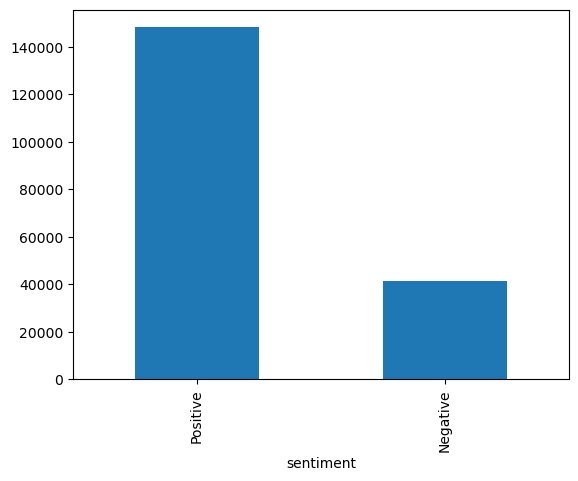

In [20]:
import matplotlib.pyplot as plt
df['sentiment'].value_counts().plot(kind='bar')

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [22]:
tfidf = TfidfVectorizer()
X = tfidf.fit_transform(df['Review'])

In [23]:
from sklearn.model_selection import train_test_split

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, df['sentiment'], test_size=0.2, random_state=42)

In [25]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [28]:
pred = model.predict(X_test)
from sklearn.metrics import accuracy_score

In [29]:
accuracy_score(y_test, pred)

0.9673180238070157